In [ ]:

# ============================================================
# RESTAURANT FOOD WASTE PREDICTION & PLANNING SYSTEM
# Step 1: Environment Setup
# ============================================================

import sys
import os
import warnings
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

warnings.filterwarnings("ignore")

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("\nEnvironment setup complete!")


Python version: 3.13.16
Pandas version: 2.2.3
NumPy version: 2.1.3

Environment setup complete!


In [ ]:

# ============================================================
# STEP 2: DOWNLOAD THE FOOD DEMAND DATASET
# ============================================================

import os
import pandas as pd

DATA_DIR = "/content/restaurant_food_waste/data"
os.makedirs(DATA_DIR, exist_ok=True)

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "devarti19/Food-Demand-Forecasting/master/"
)

files = {
    "train": "train.csv",
    "meals": "meal_info.csv",
    "centers": "fulfilment_center_info.csv",
}

datasets = {}

for name, filename in files.items():
    url = BASE_URL + filename
    print(f"Downloading {filename}...")

    datasets[name] = pd.read_csv(url)
    datasets[name].to_csv(
        os.path.join(DATA_DIR, filename),
        index=False
    )

    print(f"Loaded {name}: {datasets[name].shape}")

# Main training data
df = datasets["train"]

print("\nDataset loaded successfully!")
print("\nTraining data columns:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum().to_frame("missing_values"))


Loaded train: (456548, 9)
Loaded meals: (51, 3)
Loaded centers: (77, 5)

Dataset loaded successfully!

Training data columns:
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders']

First five rows:


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1379560,1,55,1885,136.83,152.29,0,0,177
1,1466964,1,55,1993,136.83,135.83,0,0,270
2,1346989,1,55,2539,134.86,135.86,0,0,189
3,1338232,1,55,2139,339.50,437.53,0,0,54
4,1448490,1,55,2631,243.50,242.50,0,0,40



Missing values:


,missing_values
id,0
week,0
center_id,0
meal_id,0
checkout_price,0
base_price,0
emailer_for_promotion,0
homepage_featured,0
num_orders,0


Merged dataset shape: (456548, 15)

Columns:
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders', 'category', 'cuisine', 'city_code', 'region_code', 'center_type', 'op_area']

Weekly coverage:
First week: 1
Last week: 145
Number of weeks: 145

Demand statistics:


,count,mean,std,min,25%,50%,75%,max
num_orders,456548.0,261.87276,395.922798,13.0,54.0,136.0,324.0,24299.0



Orders by week (first 10 weeks):


,week,sum,mean,count
0,1,792261,271.136550,2922
1,2,787084,271.783149,2896
2,3,695262,239.828217,2899
3,4,743529,257.365524,2889
4,5,1198675,419.263729,2859
5,6,947288,332.848911,2846
6,7,934803,334.455456,2795
7,8,670518,240.674085,2786
8,9,723243,253.413805,2854
9,10,811825,283.954180,2859



Unique meal types: 51
Unique centers: 77

Missing values after merging:


,missing_values
id,0
week,0
center_id,0
meal_id,0
checkout_price,0
base_price,0
emailer_for_promotion,0
homepage_featured,0
num_orders,0
category,0


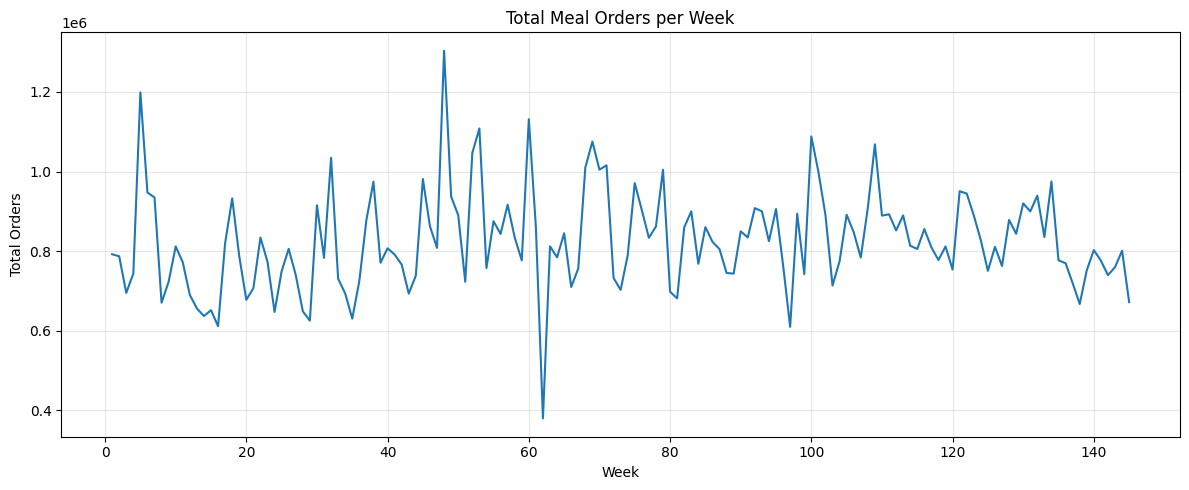

In [ ]:

# ============================================================
# STEP 3: DATA EXPLORATION & PREPARATION
# ============================================================

# 1. Merge meal and fulfillment-center metadata
df = df.merge(datasets["meals"], on="meal_id", how="left")
df = df.merge(
    datasets["centers"],
    on="center_id",
    how="left"
)

print("Merged dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# 2. Check time coverage
print("\nWeekly coverage:")
print("First week:", df["week"].min())
print("Last week:", df["week"].max())
print("Number of weeks:", df["week"].nunique())

# 3. Demand statistics
print("\nDemand statistics:")
display(df["num_orders"].describe().to_frame().T)

print("\nOrders by week (first 10 weeks):")
weekly_demand = (
    df.groupby("week")["num_orders"]
      .agg(["sum", "mean", "count"])
      .reset_index()
)

display(weekly_demand.head(10))

# 4. Unique values and metadata quality
print("\nUnique meal types:", df["meal_id"].nunique())
print("Unique centers:", df["center_id"].nunique())

print("\nMissing values after merging:")
display(df.isnull().sum().to_frame("missing_values"))

# 5. Visualise total orders per week
plt.figure(figsize=(12, 5))
plt.plot(
    weekly_demand["week"],
    weekly_demand["sum"]
)
plt.title("Total Meal Orders per Week")
plt.xlabel("Week")
plt.ylabel("Total Orders")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# STEP 4: FEATURE ENGINEERING & TIME-BASED SPLIT
# ============================================================

# Work on a separate copy
model_df = df.copy()

# Remove identifier that does not carry useful predictive meaning
model_df = model_df.drop(columns=["id"])

# Create a few simple time features
model_df["week_sin"] = np.sin(
    2 * np.pi * model_df["week"] / 52
)
model_df["week_cos"] = np.cos(
    2 * np.pi * model_df["week"] / 52
)

# Identify categorical and numerical features
target = "num_orders"

categorical_features = [
    "center_id",
    "meal_id",
    "category",
    "cuisine",
    "center_type",
    "city_code",
    "region_code",
]

numerical_features = [
    "week",
    "checkout_price",
    "base_price",
    "emailer_for_promotion",
    "homepage_featured",
    "op_area",
    "week_sin",
    "week_cos",
]

feature_columns = categorical_features + numerical_features

# Chronological split: final 20% of weeks for validation
split_week = int(model_df["week"].max() * 0.8)

train_df = model_df[model_df["week"] <= split_week].copy()
valid_df = model_df[model_df["week"] > split_week].copy()

X_train = train_df[feature_columns]
y_train = train_df[target]

X_valid = valid_df[feature_columns]
y_valid = valid_df[target]

print("Training weeks:", train_df["week"].min(), "to",
      train_df["week"].max())
print("Validation weeks:", valid_df["week"].min(), "to",
      valid_df["week"].max())

print("\nTraining rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Number of features:", len(feature_columns))

print("\nTraining target summary:")
display(y_train.describe().to_frame("training_orders").T)

print("\nValidation target summary:")
display(y_valid.describe().to_frame("validation_orders").T)


Training weeks: 1 to 116
Validation weeks: 117 to 145

Training rows: 361348
Validation rows: 95200
Number of features: 15

Training target summary:


,count,mean,std,min,25%,50%,75%,max
training_orders,361348.0,265.502017,403.547216,13.0,54.0,136.0,325.0,24299.0



Validation target summary:


,count,mean,std,min,25%,50%,75%,max
validation_orders,95200.0,248.09729,365.212366,13.0,54.0,135.0,298.0,13150.0


In [ ]:

# ============================================================
# STEP 5: AGENT 1 — DEMAND FORECASTING AGENT
# Train and compare multiple ML models
# ============================================================

import time
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Encode categorical features efficiently for a large dataset.
# Unknown categories in validation are handled safely.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=-1
                ))
            ]),
            categorical_features
        ),
        (
            "numerical",
            SimpleImputer(strategy="median"),
            numerical_features
        )
    ],
    remainder="drop"
)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )
}

results = []
trained_models = {}
predictions = {}

for name, estimator in models.items():
    print(f"\nTraining {name}...")
    start = time.time()

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)

    pred = pipeline.predict(X_valid)
    pred = np.maximum(pred, 0)  # Demand cannot be negative

    mae = mean_absolute_error(y_valid, pred)
    rmse = np.sqrt(mean_squared_error(y_valid, pred))
    wape = (
        np.abs(y_valid.to_numpy() - pred).sum()
        / np.abs(y_valid.to_numpy()).sum()
    ) * 100

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape,
        "Training time (sec)": round(time.time() - start, 2)
    })

    trained_models[name] = pipeline
    predictions[name] = pred

    print(
        f"MAE={mae:.2f} | RMSE={rmse:.2f} | "
        f"WAPE={wape:.2f}%"
    )

# Lower WAPE is better
results_df = pd.DataFrame(results).sort_values("WAPE (%)")

print("\n=== MODEL COMPARISON ===")
display(results_df.reset_index(drop=True))

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]

print(f"\nSelected model: {best_model_name}")
print("Selection criterion: Lowest validation WAPE")



Training Linear Regression...
MAE=182.70 | RMSE=317.46 | WAPE=73.64%

Training Random Forest...
MAE=83.50 | RMSE=178.41 | WAPE=33.66%

Training HistGradientBoosting...
MAE=94.15 | RMSE=186.21 | WAPE=37.95%

=== MODEL COMPARISON ===


,Model,MAE,RMSE,WAPE (%),Training time (sec)
0,Random Forest,83.504064,178.412934,33.657790,120.72
1,HistGradientBoosting,94.152133,186.208767,37.949682,5.51
2,Linear Regression,182.697169,317.460961,73.639325,3.27



Selected model: Random Forest
Selection criterion: Lowest validation WAPE


Selected model: Random Forest


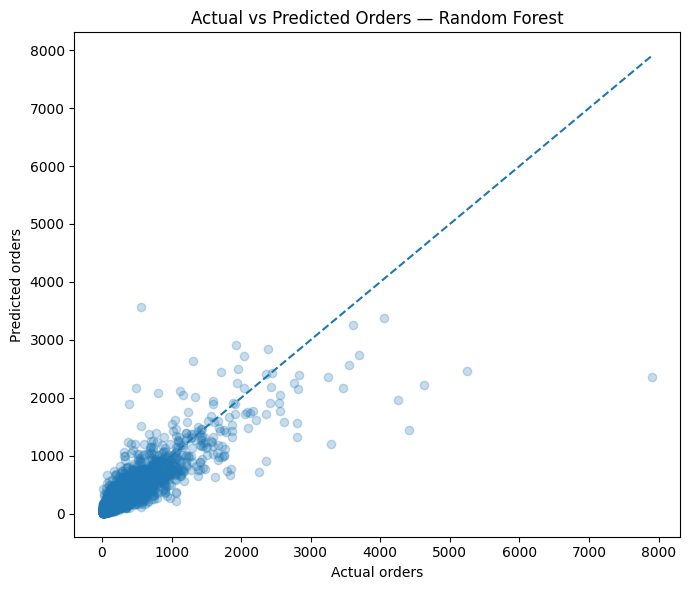

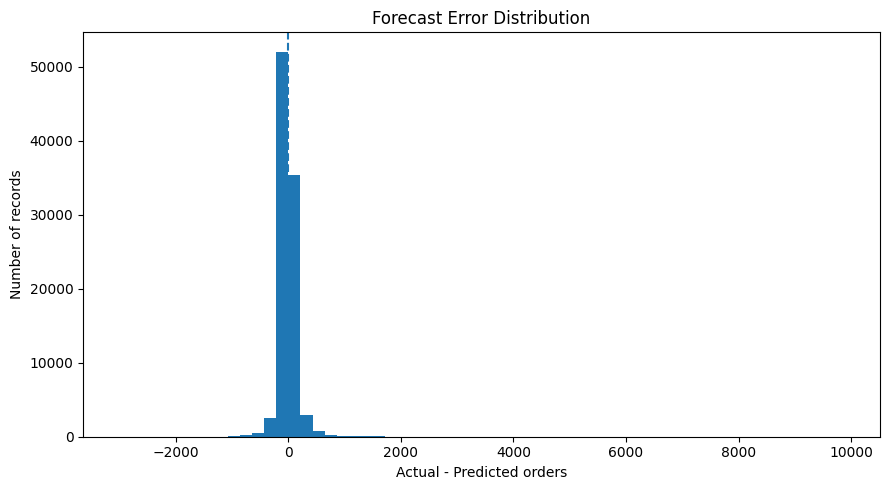


Performance by meal category:


,records,actual_orders,absolute_error,WAPE (%)
category,,,,
Pasta,5458,311741,1.795954e+05,57.610466
Seafood,5206,443970,2.163215e+05,48.724352
Fish,3968,405840,1.907476e+05,47.000688
Salad,6697,2226830,1.008847e+06,45.304177
Biryani,4275,138223,6.142586e+04,44.439684
Soup,2606,286360,1.264142e+05,44.145215
Starters,5872,722614,3.140346e+05,43.458145
Desert,6166,474778,1.959778e+05,41.277781
Pizza,6671,1513160,5.566505e+05,36.787289


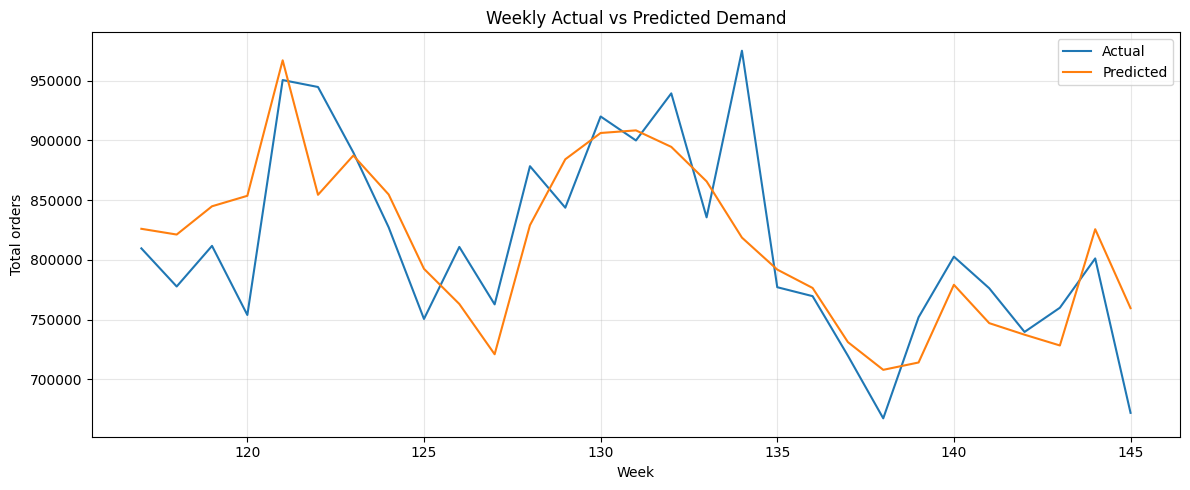

In [ ]:

# ============================================================
# STEP 6: EVALUATE THE SELECTED FORECASTING MODEL
# ============================================================

# Actual vs predicted demand
evaluation_df = valid_df[["week", "center_id", "meal_id"]].copy()
evaluation_df["actual_orders"] = y_valid.to_numpy()
evaluation_df["predicted_orders"] = best_predictions
evaluation_df["error"] = (
    evaluation_df["actual_orders"]
    - evaluation_df["predicted_orders"]
)
evaluation_df["absolute_error"] = evaluation_df["error"].abs()

print("Selected model:", best_model_name)

# 1. Actual vs predicted scatter plot (sample for readability)
plot_sample = evaluation_df.sample(
    n=min(5000, len(evaluation_df)),
    random_state=42
)

plt.figure(figsize=(7, 6))
plt.scatter(
    plot_sample["actual_orders"],
    plot_sample["predicted_orders"],
    alpha=0.25
)

max_value = max(
    plot_sample["actual_orders"].max(),
    plot_sample["predicted_orders"].max()
)

plt.plot([0, max_value], [0, max_value], linestyle="--")
plt.xlabel("Actual orders")
plt.ylabel("Predicted orders")
plt.title(f"Actual vs Predicted Orders — {best_model_name}")
plt.tight_layout()
plt.show()

# 2. Error distribution
plt.figure(figsize=(9, 5))
plt.hist(evaluation_df["error"], bins=60)
plt.axvline(0, linestyle="--")
plt.xlabel("Actual - Predicted orders")
plt.ylabel("Number of records")
plt.title("Forecast Error Distribution")
plt.tight_layout()
plt.show()

# 3. Performance by meal category
category_eval = evaluation_df.join(
    valid_df[["category"]]
)

category_summary = (
    category_eval.groupby("category")
    .agg(
        records=("actual_orders", "size"),
        actual_orders=("actual_orders", "sum"),
        absolute_error=("absolute_error", "sum")
    )
)

category_summary["WAPE (%)"] = (
    100 * category_summary["absolute_error"]
    / category_summary["actual_orders"]
)

print("\nPerformance by meal category:")
display(
    category_summary.sort_values("WAPE (%)", ascending=False)
)

# 4. Aggregate forecast versus actual by week
weekly_eval = (
    evaluation_df.groupby("week")
    .agg(
        actual_orders=("actual_orders", "sum"),
        predicted_orders=("predicted_orders", "sum")
    )
    .reset_index()
)

plt.figure(figsize=(12, 5))
plt.plot(
    weekly_eval["week"],
    weekly_eval["actual_orders"],
    label="Actual"
)
plt.plot(
    weekly_eval["week"],
    weekly_eval["predicted_orders"],
    label="Predicted"
)
plt.xlabel("Week")
plt.ylabel("Total orders")
plt.title("Weekly Actual vs Predicted Demand")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# STEP 7: TEST CATBOOST AS AN ALTERNATIVE
# ============================================================

%pip -q install catboost

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import time

# CatBoost accepts categorical columns directly.
# Convert categorical values to strings and preserve the
# original train/validation split.
X_train_cb = X_train.copy()
X_valid_cb = X_valid.copy()

cat_features = categorical_features.copy()

for col in cat_features:
    X_train_cb[col] = X_train_cb[col].astype(str)
    X_valid_cb[col] = X_valid_cb[col].astype(str)

catboost_model = CatBoostRegressor(
    iterations=700,
    depth=8,
    learning_rate=0.08,
    loss_function="RMSE",
    verbose=100,
    random_seed=42,
    allow_writing_files=False
)

print("Training CatBoost...")
start = time.time()

catboost_model.fit(
    X_train_cb,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid_cb, y_valid),
    early_stopping_rounds=60,
    verbose=100
)

catboost_pred = np.maximum(
    catboost_model.predict(X_valid_cb), 0
)

catboost_mae = mean_absolute_error(y_valid, catboost_pred)
catboost_rmse = np.sqrt(
    mean_squared_error(y_valid, catboost_pred)
)
catboost_wape = (
    np.abs(y_valid.to_numpy() - catboost_pred).sum()
    / np.abs(y_valid.to_numpy()).sum()
) * 100

catboost_time = time.time() - start

print("\n=== CATBOOST RESULTS ===")
print(f"MAE: {catboost_mae:.2f}")
print(f"RMSE: {catboost_rmse:.2f}")
print(f"WAPE: {catboost_wape:.2f}%")
print(f"Training time: {catboost_time:.2f} seconds")

# Compare with the existing models
comparison = results_df[
    ["Model", "MAE", "RMSE", "WAPE (%)", "Training time (sec)"]
].copy()

comparison = pd.concat([
    comparison,
    pd.DataFrame([{
        "Model": "CatBoost",
        "MAE": catboost_mae,
        "RMSE": catboost_rmse,
        "WAPE (%)": catboost_wape,
        "Training time (sec)": round(catboost_time, 2)
    }])
], ignore_index=True)

comparison = comparison.sort_values("WAPE (%)").reset_index(drop=True)

print("\n=== UPDATED MODEL COMPARISON ===")
display(comparison)

best_candidate = comparison.iloc[0]["Model"]
print("\nBest candidate so far:", best_candidate)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.6 MB/s eta 0:00:00
Training CatBoost...
0:	learn: 384.3073071	test: 348.5033122	best: 348.5033122 (0)	total: 577ms	remaining: 6m 43s
100:	learn: 175.2013837	test: 178.3138588	best: 178.3138588 (100)	total: 43.8s	remaining: 4m 19s
200:	learn: 156.0329234	test: 170.0576741	best: 170.0576741 (200)	total: 1m 35s	remaining: 3m 56s
300:	learn: 145.0052149	test: 167.8863753	best: 167.8824999 (298)	total: 2m 22s	remaining: 3m 8s
400:	learn: 138.0117317	test: 166.9424842	best: 166.9134549 (394)	total: 3m 10s	remaining: 2m 22s
500:	learn: 132.8669391	test: 166.0789124	best: 166.0154958 (486)	total: 3m 58s	remaining: 1m 34s
600:	learn: 129.0084028	test: 165.7956988	best: 165.7046394 (575)	total: 4m 49s	remaining: 47.6s
Stopped by overfitting detector  (60 iterations wait)

bestTest = 165.7046394
bestIteration = 575

Shrink model to first 576 iterations.

=== CATBOOST RESULTS ===
MAE: 80.42
RMSE: 165.70
WAPE: 32.42%
Training time: 309.25 

,Model,MAE,RMSE,WAPE (%),Training time (sec)
0,CatBoost,80.422957,165.701542,32.415895,309.25
1,Random Forest,83.504064,178.412934,33.657790,120.72
2,HistGradientBoosting,94.152133,186.208767,37.949682,5.51
3,Linear Regression,182.697169,317.460961,73.639325,3.27



Best candidate so far: CatBoost


In [ ]:

# ============================================================
# STEP 8: FINALISE AGENT 1 AND SAVE MODEL ARTIFACTS
# ============================================================

import os
import json
import joblib
import pandas as pd

ARTIFACT_DIR = "/content/restaurant_food_waste/artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Select best model based on validation WAPE
if catboost_wape < results_df["WAPE (%)"].min():
    selected_model_name = "CatBoost"
    selected_model = catboost_model
    selected_prediction = catboost_pred
    selected_wape = catboost_wape
    selected_mae = catboost_mae
    selected_rmse = catboost_rmse
else:
    best_row = results_df.sort_values("WAPE (%)").iloc[0]
    selected_model_name = best_row["Model"]
    selected_model = trained_models[selected_model_name]
    selected_prediction = predictions[selected_model_name]
    selected_wape = best_row["WAPE (%)"]
    selected_mae = best_row["MAE"]
    selected_rmse = best_row["RMSE"]

# Save trained model
model_path = os.path.join(ARTIFACT_DIR, "demand_forecasting_model.joblib")
joblib.dump(selected_model, model_path)

# Save comparison report
comparison.to_csv(
    os.path.join(ARTIFACT_DIR, "model_comparison.csv"),
    index=False
)

# Save metadata needed to understand the model
metadata = {
    "agent": "Demand Forecasting Agent",
    "selected_model": selected_model_name,
    "selection_metric": "validation WAPE",
    "validation_wape_percent": float(selected_wape),
    "validation_mae": float(selected_mae),
    "validation_rmse": float(selected_rmse),
    "training_weeks": [int(train_df["week"].min()),
                       int(train_df["week"].max())],
    "validation_weeks": [int(valid_df["week"].min()),
                         int(valid_df["week"].max())],
    "target": "num_orders",
    "features": feature_columns,
    "note": "Results are from a chronological holdout on the public meal-demand dataset."
}

with open(
    os.path.join(ARTIFACT_DIR, "model_metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=2)

# Create a validation prediction report
forecast_report = valid_df[
    ["week", "center_id", "meal_id", "category"]
].copy()

forecast_report["actual_orders"] = y_valid.to_numpy()
forecast_report["predicted_orders"] = selected_prediction
forecast_report["absolute_error"] = (
    forecast_report["actual_orders"]
    - forecast_report["predicted_orders"]
).abs()

forecast_report.to_csv(
    os.path.join(ARTIFACT_DIR, "validation_forecasts.csv"),
    index=False
)

print("Agent 1 model saved!")
print("Selected model:", selected_model_name)
print(f"Validation WAPE: {selected_wape:.2f}%")
print(f"Validation MAE: {selected_mae:.2f}")
print(f"Validation RMSE: {selected_rmse:.2f}")
print("\nSaved artifacts:")
print(os.listdir(ARTIFACT_DIR))


Agent 1 model saved!
Selected model: CatBoost
Validation WAPE: 32.42%
Validation MAE: 80.42
Validation RMSE: 165.70

Saved artifacts:
['demand_forecasting_model.joblib', 'validation_forecasts.csv', 'model_comparison.csv', 'model_metadata.json']


# Agent 2

In [ ]:

# ============================================================
# STEP 9: AGENT 2 — PREPARATION PLANNING AGENT
# ============================================================

import numpy as np
import pandas as pd
import math

class PreparationPlanningAgent:
    """
    Converts forecasted demand into preparation recommendations.

    Inputs:
      - Forecasted demand
      - Usable prepared stock
      - Safety buffer percentage

    Output:
      - Recommended additional preparation quantity
    """

    def __init__(self, safety_buffer=0.10):
        if safety_buffer < 0:
            raise ValueError("Safety buffer cannot be negative.")

        self.safety_buffer = safety_buffer

    def recommend(self, forecast_demand, usable_stock=0):
        if forecast_demand < 0 or usable_stock < 0:
            raise ValueError(
                "Forecast demand and usable stock must be non-negative."
            )

        target_quantity = math.ceil(
            forecast_demand * (1 + self.safety_buffer) - 1e-9
        )

        preparation_quantity = max(
            0,
            target_quantity - math.floor(usable_stock)
        )

        return {
            "forecast_demand": float(forecast_demand),
            "safety_buffer_pct": self.safety_buffer * 100,
            "target_quantity": target_quantity,
            "usable_stock": math.floor(usable_stock),
            "recommended_to_prepare": preparation_quantity
        }

    def plan_table(
        self,
        forecast_table,
        stock_column="usable_stock",
        demand_column="predicted_orders"
    ):
        required_columns = {demand_column, stock_column}

        if not required_columns.issubset(forecast_table.columns):
            raise ValueError(
                f"Input table must contain {required_columns}"
            )

        output = forecast_table.copy()

        output["target_quantity"] = np.ceil(
            output[demand_column] * (1 + self.safety_buffer)
        ).astype(int)

        output["recommended_to_prepare"] = (
            output["target_quantity"]
            - np.floor(output[stock_column]).astype(int)
        ).clip(lower=0)

        return output


# Instantiate the agent
planning_agent = PreparationPlanningAgent(safety_buffer=0.10)

# Demonstrate with example values
example_cases = pd.DataFrame([
    {"meal": "Meal A", "predicted_orders": 100, "usable_stock": 20},
    {"meal": "Meal B", "predicted_orders": 250, "usable_stock": 40},
    {"meal": "Meal C", "predicted_orders": 75, "usable_stock": 100},
])

example_plan = planning_agent.plan_table(example_cases)

print("Preparation Planning Agent — Demonstration")
display(example_plan)

# Unit-style sanity checks
assert planning_agent.recommend(100, 20)["recommended_to_prepare"] == 90
assert planning_agent.recommend(75, 100)["recommended_to_prepare"] == 0
assert planning_agent.recommend(100, 0)["recommended_to_prepare"] == 110

print("All preparation planning checks passed!")


Preparation Planning Agent — Demonstration


,meal,predicted_orders,usable_stock,target_quantity,recommended_to_prepare
0,Meal A,100,20,111,91
1,Meal B,250,40,275,235
2,Meal C,75,100,83,0


AssertionError: 

In [ ]:

# ============================================================
# FIX: PREPARATION PLANNING AGENT ROUNDING
# ============================================================

import math
import numpy as np
import pandas as pd

class PreparationPlanningAgent:
    def __init__(self, safety_buffer=0.10):
        if safety_buffer < 0:
            raise ValueError("Safety buffer cannot be negative.")
        self.safety_buffer = safety_buffer

    def recommend(self, forecast_demand, usable_stock=0):
        if forecast_demand < 0 or usable_stock < 0:
            raise ValueError(
                "Forecast demand and usable stock must be non-negative."
            )

        target_quantity = math.ceil(
            forecast_demand * (1 + self.safety_buffer) - 1e-9
        )

        preparation_quantity = max(
            0, target_quantity - math.floor(usable_stock)
        )

        return {
            "forecast_demand": float(forecast_demand),
            "safety_buffer_pct": self.safety_buffer * 100,
            "target_quantity": target_quantity,
            "usable_stock": math.floor(usable_stock),
            "recommended_to_prepare": preparation_quantity
        }

    def plan_table(
        self,
        forecast_table,
        stock_column="usable_stock",
        demand_column="predicted_orders"
    ):
        required = {demand_column, stock_column}
        if not required.issubset(forecast_table.columns):
            raise ValueError(f"Missing required columns: {required}")

        output = forecast_table.copy()

        output["target_quantity"] = np.ceil(
            output[demand_column] * (1 + self.safety_buffer) - 1e-9
        ).astype(int)

        output["recommended_to_prepare"] = (
            output["target_quantity"]
            - np.floor(output[stock_column]).astype(int)
        ).clip(lower=0)

        return output


# Recreate agent using corrected implementation
planning_agent = PreparationPlanningAgent(safety_buffer=0.10)

# Run sanity checks
assert planning_agent.recommend(100, 20)["recommended_to_prepare"] == 90
assert planning_agent.recommend(75, 100)["recommended_to_prepare"] == 0
assert planning_agent.recommend(100, 0)["recommended_to_prepare"] == 110

example_plan = planning_agent.plan_table(example_cases)
display(example_plan)

print("All preparation planning checks passed!")


,meal,predicted_orders,usable_stock,target_quantity,recommended_to_prepare
0,Meal A,100,20,110,90
1,Meal B,250,40,275,235
2,Meal C,75,100,83,0


All preparation planning checks passed!


In [ ]:

# ============================================================
# STEP 10: INTEGRATE FORECASTING + PLANNING AGENTS
# ============================================================

# Build a sample from the selected model's validation predictions
integration_df = valid_df[
    ["week", "center_id", "meal_id", "category"]
].copy()

integration_df["predicted_orders"] = selected_prediction

# Use a small sample for demonstration
integration_df = integration_df.sample(
    n=10, random_state=42
).copy()

# Demonstration inventory only — replace with real stock data later
rng = np.random.default_rng(42)
integration_df["usable_stock"] = rng.integers(
    low=0, high=150, size=len(integration_df)
)

# Apply Agent 2
integrated_plan = planning_agent.plan_table(integration_df)

# Show the final recommendations
display_columns = [
    "week",
    "center_id",
    "meal_id",
    "category",
    "predicted_orders",
    "usable_stock",
    "target_quantity",
    "recommended_to_prepare"
]

print("INTEGRATED FORECAST + PREPARATION PLAN")
print("Note: usable_stock values are simulated for demonstration.")
display(
    integrated_plan[display_columns].round(
        {"predicted_orders": 2}
    )
)

# Save the integrated output
integration_path = os.path.join(
    ARTIFACT_DIR, "integrated_preparation_plan.csv"
)

integrated_plan.to_csv(integration_path, index=False)

print("\nIntegrated plan saved to:", integration_path)


INTEGRATED FORECAST + PREPARATION PLAN
Note: usable_stock values are simulated for demonstration.


,week,center_id,meal_id,category,predicted_orders,usable_stock,target_quantity,recommended_to_prepare
418117,134,91,1971,Sandwich,167.48,13,185,172
376627,121,67,2322,Beverages,382.91,116,422,306
394383,127,13,1885,Beverages,2308.62,98,2540,2442
393732,126,43,2490,Salad,2251.63,65,2477,2412
398196,128,108,1778,Beverages,534.20,64,588,524
448382,143,139,1885,Beverages,196.86,128,217,89
401796,129,137,1902,Biryani,47.65,12,53,41
401469,129,108,1993,Beverages,904.94,104,996,892
385726,124,177,2581,Pizza,138.93,30,153,123
417448,134,109,1543,Desert,59.00,14,65,51



Integrated plan saved to: /content/restaurant_food_waste/artifacts/integrated_preparation_plan.csv


In [ ]:

%pip -q install shap


Top features influencing demand predictions:


,feature,mean_abs_shap
1,meal_id,125.970458
8,checkout_price,67.940288
0,center_id,56.400105
10,emailer_for_promotion,40.363065
11,homepage_featured,21.078433
3,cuisine,17.625032
2,category,16.153462
9,base_price,15.553594
12,op_area,14.968921
6,region_code,10.624167


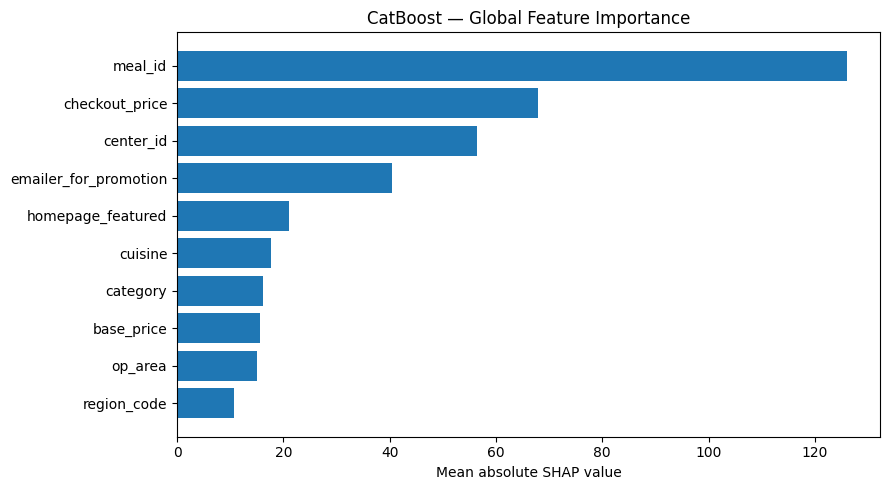

SHAP feature importance saved.


In [ ]:

# ============================================================
# STEP 11: AGENT 3 — XAI & WASTE MONITORING
# PART A: SHAP EXPLANATIONS
# ============================================================

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Explain a manageable sample of validation records
X_explain = X_valid_cb.sample(
    n=min(300, len(X_valid_cb)),
    random_state=42
).copy()

# CatBoost's native SHAP calculation
shap_values = catboost_model.get_feature_importance(
    data=catboost_model.__class__.__module__ and
         __import__("catboost").Pool(
             X_explain,
             cat_features=cat_features
         ),
    type="ShapValues"
)

# Final SHAP column is the expected/base value
feature_shap_values = shap_values[:, :-1]

# Global feature importance: mean absolute SHAP value
shap_importance = pd.DataFrame({
    "feature": X_explain.columns,
    "mean_abs_shap": np.abs(feature_shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

print("Top features influencing demand predictions:")
display(shap_importance.head(10))

# Plot global feature importance
plt.figure(figsize=(9, 5))
top_features = shap_importance.head(10).sort_values(
    "mean_abs_shap"
)

plt.barh(
    top_features["feature"],
    top_features["mean_abs_shap"]
)
plt.xlabel("Mean absolute SHAP value")
plt.title("CatBoost — Global Feature Importance")
plt.tight_layout()
plt.show()

# Save explanation results
shap_importance.to_csv(
    os.path.join(ARTIFACT_DIR, "shap_feature_importance.csv"),
    index=False
)

print("SHAP feature importance saved.")


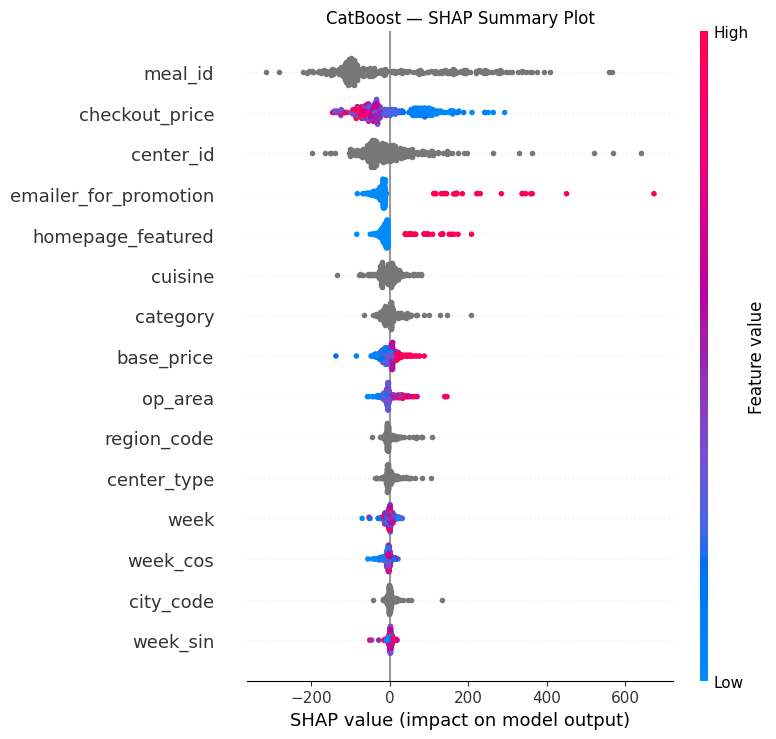

In [ ]:
import shap
import matplotlib.pyplot as plt
from catboost import Pool

# Use a manageable sample of validation data
X_explain = X_valid_cb.sample(
    n=min(300, len(X_valid_cb)),
    random_state=42
).copy()

# Calculate CatBoost SHAP values
explain_pool = Pool(
    X_explain,
    cat_features=cat_features
)

shap_values = catboost_model.get_feature_importance(
    data=explain_pool,
    type="ShapValues"
)

# Remove the final expected-value column
feature_shap_values = shap_values[:, :-1]

# Plot global feature impact
shap.summary_plot(
    feature_shap_values,
    X_explain,
    plot_type="dot",
    max_display=15,
    show=False
)

plt.title("CatBoost — SHAP Summary Plot")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

class WasteMonitoringAgent:
    """
    Monitors demand forecast accuracy and potential surplus.

    Actual waste is reported only when measured waste data is supplied.
    Forecast surplus alone is not proof of food waste.
    """

    def monitor(
        self,
        actual_orders,
        predicted_orders,
        prepared_quantity=None,
        measured_waste=None
    ):
        actual = max(0, int(round(actual_orders)))
        predicted = max(0, int(round(predicted_orders)))

        result = {
            "actual_orders": actual,
            "predicted_orders": predicted,
            "forecast_error": actual - predicted,
            "absolute_error": abs(actual - predicted),
            "potential_surplus": None,
            "measured_waste": None,
            "status": None
        }

        if prepared_quantity is not None:
            prepared = max(0, int(round(prepared_quantity)))
            result["potential_surplus"] = max(0, prepared - actual)

            if prepared < actual:
                result["status"] = "Potential under-preparation"
            elif prepared > actual:
                result["status"] = "Potential surplus"
            else:
                result["status"] = "Preparation matched demand"

        if measured_waste is not None:
            result["measured_waste"] = max(
                0, float(measured_waste)
            )

        return result


waste_agent = WasteMonitoringAgent()

# Example demonstration — simulated quantities, not real waste records
demo_result = waste_agent.monitor(
    actual_orders=100,
    predicted_orders=110,
    prepared_quantity=120,
    measured_waste=None
)

display(pd.DataFrame([demo_result]))

,actual_orders,predicted_orders,forecast_error,absolute_error,potential_surplus,measured_waste,status
0,100,110,-10,10,20,None,Potential surplus


In [ ]:
display(pd.DataFrame([demo_result]).T.rename(
    columns={0: "Value"}
))

,Value
actual_orders,100
predicted_orders,110
forecast_error,-10
absolute_error,10
potential_surplus,20
measured_waste,None
status,Potential surplus


In [ ]:
# Agent 1: Demand forecasting output
final_df = valid_df[
    ["week", "center_id", "meal_id", "category"]
].copy()

final_df["actual_orders"] = y_valid.to_numpy()
final_df["predicted_orders"] = np.maximum(
    selected_prediction, 0
).round().astype(int)

# Agent 2: Preparation planning
# For this demonstration, stock is simulated.
rng = np.random.default_rng(42)

final_df["usable_stock"] = rng.integers(
    low=0, high=150, size=len(final_df)
)

final_df = planning_agent.plan_table(
    final_df,
    stock_column="usable_stock",
    demand_column="predicted_orders"
)

final_df["prepared_quantity"] = (
    final_df["recommended_to_prepare"]
    + final_df["usable_stock"]
)

# Agent 3: XAI and waste monitoring
final_df["forecast_error"] = (
    final_df["actual_orders"] - final_df["predicted_orders"]
)

final_df["absolute_error"] = (
    final_df["forecast_error"].abs()
)

final_df["potential_surplus"] = (
    final_df["prepared_quantity"]
    - final_df["actual_orders"]
).clip(lower=0)

final_df["monitoring_status"] = np.select(
    [
        final_df["prepared_quantity"] < final_df["actual_orders"],
        final_df["potential_surplus"] > 0
    ],
    [
        "Potential under-preparation",
        "Potential surplus"
    ],
    default="Preparation matched demand"
)

# Actual waste is not in the source dataset.
final_df["measured_waste"] = np.nan

# Review sample results
display(final_df.head(10))

# Forecast performance on the validation period
mae = final_df["absolute_error"].mean()
rmse = np.sqrt(
    (final_df["forecast_error"] ** 2).mean()
)

print(f"Validation MAE: {mae:.2f}")
print(f"Validation RMSE: {rmse:.2f}")
print(
    "Potential-surplus records:",
    int((final_df["potential_surplus"] > 0).sum())
)

# Save integrated output
output_path = (
    "/content/restaurant_food_waste/artifacts/"
    "final_integrated_results.csv"
)

final_df.to_csv(output_path, index=False)
print(f"Saved integrated results to: {output_path}")

,week,center_id,meal_id,category,actual_orders,predicted_orders,usable_stock,target_quantity,recommended_to_prepare,prepared_quantity,forecast_error,absolute_error,potential_surplus,monitoring_status,measured_waste
361348,117,55,1885,Beverages,162,296,13,326,313,326,-134,134,164,Potential surplus,NaN
361349,117,55,1993,Beverages,135,274,116,302,186,302,-139,139,167,Potential surplus,NaN
361350,117,55,2539,Beverages,163,169,98,186,88,186,-6,6,23,Potential surplus,NaN
361351,117,55,2139,Beverages,41,23,65,26,0,65,18,18,24,Potential surplus,NaN
361352,117,55,2631,Beverages,81,54,64,60,0,64,27,27,0,Potential under-preparation,NaN
361353,117,55,1248,Beverages,28,42,128,47,0,128,-14,14,100,Potential surplus,NaN
361354,117,55,1778,Beverages,297,214,12,236,224,236,83,83,0,Potential under-preparation,NaN
361355,117,55,1062,Beverages,216,274,104,302,198,302,-58,58,86,Potential surplus,NaN
361356,117,55,2707,Beverages,514,292,30,322,292,322,222,222,0,Potential under-preparation,NaN
361357,117,55,1207,Beverages,217,114,14,126,112,126,103,103,0,Potential under-preparation,NaN


Validation MAE: 80.42
Validation RMSE: 165.70
Potential-surplus records: 65721
Saved integrated results to: /content/restaurant_food_waste/artifacts/final_integrated_results.csv


In [ ]:
# Separate planning-time decisions from post-service evaluation.

final_df["recommended_to_prepare"] = (
    final_df["target_quantity"] - final_df["usable_stock"]
).clip(lower=0)

# Quantity planned for availability = existing usable stock + new preparation
final_df["planned_available_quantity"] = (
    final_df["usable_stock"] + final_df["recommended_to_prepare"]
)

# Post-service monitoring: compare planned availability with actual orders.
final_df["potential_surplus"] = (
    final_df["planned_available_quantity"]
    - final_df["actual_orders"]
).clip(lower=0)

final_df["potential_shortfall"] = (
    final_df["actual_orders"]
    - final_df["planned_available_quantity"]
).clip(lower=0)

final_df["monitoring_status"] = np.select(
    [
        final_df["potential_shortfall"] > 0,
        final_df["potential_surplus"] > 0
    ],
    [
        "Potential under-preparation",
        "Potential surplus"
    ],
    default="Availability matched actual orders"
)

# This dataset does not contain measured waste.
final_df["measured_waste"] = np.nan

display(final_df[
    [
        "week", "center_id", "meal_id",
        "actual_orders", "predicted_orders",
        "usable_stock", "target_quantity",
        "recommended_to_prepare",
        "planned_available_quantity",
        "forecast_error", "potential_surplus",
        "potential_shortfall", "monitoring_status",
        "measured_waste"
    ]
].head(10))

print("Validation MAE:", round(final_df["absolute_error"].mean(), 2))
print(
    "Potential-surplus records:",
    int((final_df["potential_surplus"] > 0).sum())
)
print(
    "Potential-shortfall records:",
    int((final_df["potential_shortfall"] > 0).sum())
)

output_path = (
    "/content/restaurant_food_waste/artifacts/"
    "final_integrated_results.csv"
)
final_df.to_csv(output_path, index=False)
print("Updated output saved:", output_path)

,week,center_id,meal_id,actual_orders,predicted_orders,usable_stock,target_quantity,recommended_to_prepare,planned_available_quantity,forecast_error,potential_surplus,potential_shortfall,monitoring_status,measured_waste
361348,117,55,1885,162,296,13,326,313,326,-134,164,0,Potential surplus,NaN
361349,117,55,1993,135,274,116,302,186,302,-139,167,0,Potential surplus,NaN
361350,117,55,2539,163,169,98,186,88,186,-6,23,0,Potential surplus,NaN
361351,117,55,2139,41,23,65,26,0,65,18,24,0,Potential surplus,NaN
361352,117,55,2631,81,54,64,60,0,64,27,0,17,Potential under-preparation,NaN
361353,117,55,1248,28,42,128,47,0,128,-14,100,0,Potential surplus,NaN
361354,117,55,1778,297,214,12,236,224,236,83,0,61,Potential under-preparation,NaN
361355,117,55,1062,216,274,104,302,198,302,-58,86,0,Potential surplus,NaN
361356,117,55,2707,514,292,30,322,292,322,222,0,192,Potential under-preparation,NaN
361357,117,55,1207,217,114,14,126,112,126,103,0,91,Potential under-preparation,NaN


Validation MAE: 80.42
Potential-surplus records: 65721
Potential-shortfall records: 29082
Updated output saved: /content/restaurant_food_waste/artifacts/final_integrated_results.csv


In [ ]:
# Recalculate the planning columns from the current source columns
final_df["target_quantity"] = np.ceil(
    final_df["predicted_orders"] * (1 + planning_agent.safety_buffer) - 1e-9
).astype(int)

final_df["usable_stock"] = final_df["usable_stock"].clip(lower=0).astype(int)

final_df["recommended_to_prepare"] = (
    final_df["target_quantity"] - final_df["usable_stock"]
).clip(lower=0).astype(int)

final_df["planned_available_quantity"] = (
    final_df["usable_stock"] + final_df["recommended_to_prepare"]
)

# Diagnose any rows that do not satisfy the expected relationship
check = final_df[
    final_df["planned_available_quantity"] != final_df["target_quantity"]
]

print("Rows failing planning consistency check:", len(check))

if len(check) > 0:
    display(check[
        [
            "predicted_orders",
            "usable_stock",
            "target_quantity",
            "recommended_to_prepare",
            "planned_available_quantity",
        ]
    ].head(10))
else:
    print("Planning quantities are internally consistent.")

Rows failing planning consistency check: 23336


,predicted_orders,usable_stock,target_quantity,recommended_to_prepare,planned_available_quantity
3,23,65,26,0,65
4,54,64,60,0,64
5,42,128,47,0,128
11,118,146,130,0,146
15,31,117,35,0,117
16,32,76,36,0,76
18,40,125,44,0,125
19,30,67,33,0,67
20,24,75,27,0,75
24,72,117,80,0,117


In [ ]:
assert (
    final_df["target_quantity"] >= final_df["predicted_orders"]
).all()

assert (
    final_df["planned_available_quantity"]
    == final_df[["usable_stock", "target_quantity"]].max(axis=1)
).all()

assert (
    final_df["potential_surplus"] * final_df["potential_shortfall"]
    == 0
).all()

final_df.to_csv(
    "/content/restaurant_food_waste/artifacts/final_integrated_results.csv",
    index=False
)

print("All checks passed. Integrated results saved successfully.")

All checks passed. Integrated results saved successfully.


# **Step 1 — Rebuild and validate the final results**

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

# Ensure the output directory exists
artifact_dir = Path("/content/restaurant_food_waste/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

# Agent 2: Preparation planning
buffer = planning_agent.safety_buffer

final_df["target_quantity"] = np.ceil(
    final_df["predicted_orders"] * (1 + buffer) - 1e-9
).astype(int)

final_df["usable_stock"] = (
    final_df["usable_stock"].clip(lower=0).astype(int)
)

final_df["recommended_to_prepare"] = (
    final_df["target_quantity"] - final_df["usable_stock"]
).clip(lower=0).astype(int)

final_df["planned_available_quantity"] = (
    final_df["usable_stock"]
    + final_df["recommended_to_prepare"]
)

# Agent 3: Post-service monitoring
final_df["forecast_error"] = (
    final_df["actual_orders"] - final_df["predicted_orders"]
)
final_df["absolute_error"] = final_df["forecast_error"].abs()

final_df["potential_surplus"] = (
    final_df["planned_available_quantity"]
    - final_df["actual_orders"]
).clip(lower=0)

final_df["potential_shortfall"] = (
    final_df["actual_orders"]
    - final_df["planned_available_quantity"]
).clip(lower=0)

final_df["monitoring_status"] = np.select(
    [
        final_df["potential_shortfall"] > 0,
        final_df["potential_surplus"] > 0
    ],
    [
        "Potential under-preparation",
        "Potential surplus"
    ],
    default="Availability matched actual orders"
)

# No measured waste data exists in the source dataset
final_df["measured_waste"] = np.nan

# Consistency checks
assert (
    final_df["target_quantity"] >= final_df["predicted_orders"]
).all()

assert (
    final_df["planned_available_quantity"]
    == final_df[["usable_stock", "target_quantity"]].max(axis=1)
).all()

assert (
    (final_df["potential_surplus"] == 0)
    | (final_df["potential_shortfall"] == 0)
).all()

# Recalculate validation metrics
mae = final_df["absolute_error"].mean()
rmse = np.sqrt((final_df["forecast_error"] ** 2).mean())
wape = (
    final_df["absolute_error"].sum()
    / final_df["actual_orders"].sum()
    * 100
)

print("All consistency checks passed.")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"WAPE: {wape:.2f}%")
print("Potential-surplus records:",
      int((final_df["potential_surplus"] > 0).sum()))
print("Potential-shortfall records:",
      int((final_df["potential_shortfall"] > 0).sum()))

final_df.to_csv(
    artifact_dir / "final_integrated_results.csv",
    index=False
)

display(final_df.head(10))


All consistency checks passed.
MAE: 80.42
RMSE: 165.70
WAPE: 32.42%
Potential-surplus records: 65721
Potential-shortfall records: 29082


,week,center_id,meal_id,category,actual_orders,predicted_orders,usable_stock,target_quantity,recommended_to_prepare,planned_available_quantity,forecast_error,absolute_error,potential_surplus,potential_shortfall,monitoring_status,measured_waste
0,117,55,1885,Beverages,162,296,13,326,313,326,-134,134,164,0,Potential surplus,NaN
1,117,55,1993,Beverages,135,274,116,302,186,302,-139,139,167,0,Potential surplus,NaN
2,117,55,2539,Beverages,163,169,98,186,88,186,-6,6,23,0,Potential surplus,NaN
3,117,55,2139,Beverages,41,23,65,26,0,65,18,18,24,0,Potential surplus,NaN
4,117,55,2631,Beverages,81,54,64,60,0,64,27,27,0,17,Potential under-preparation,NaN
5,117,55,1248,Beverages,28,42,128,47,0,128,-14,14,100,0,Potential surplus,NaN
6,117,55,1778,Beverages,297,214,12,236,224,236,83,83,0,61,Potential under-preparation,NaN
7,117,55,1062,Beverages,216,274,104,302,198,302,-58,58,86,0,Potential surplus,NaN
8,117,55,2707,Beverages,514,292,30,322,292,322,222,222,0,192,Potential under-preparation,NaN
9,117,55,1207,Beverages,217,114,14,126,112,126,103,103,0,91,Potential under-preparation,NaN


# **Step 2 — Generate the final model comparison report**

In [ ]:

# Use the comparison table already created during model evaluation
display(comparison.sort_values("WAPE (%)").reset_index(drop=True))

comparison.to_csv(
    artifact_dir / "model_comparison_final.csv",
    index=False
)

print("Selected model:", selected_model_name)
print(f"Selected-model validation MAE: {selected_mae:.2f}")
print(f"Selected-model validation RMSE: {selected_rmse:.2f}")
print(f"Selected-model validation WAPE: {selected_wape:.2f}%")


,Model,MAE,RMSE,WAPE (%),Training time (sec)
0,CatBoost,80.422957,165.701542,32.415895,309.25
1,Random Forest,83.504064,178.412934,33.657790,120.72
2,HistGradientBoosting,94.152133,186.208767,37.949682,5.51
3,Linear Regression,182.697169,317.460961,73.639325,3.27


Selected model: CatBoost
Selected-model validation MAE: 80.42
Selected-model validation RMSE: 165.70
Selected-model validation WAPE: 32.42%


# **Step 3 — Save your artifacts to Google Drive**

In [ ]:

from google.colab import drive
drive.mount("/content/drive")

import shutil

drive_dir = Path(
    "/content/drive/MyDrive/Restaurant_Food_Waste_Project"
)
drive_dir.mkdir(parents=True, exist_ok=True)

for file_path in artifact_dir.iterdir():
    if file_path.is_file():
        shutil.copy2(file_path, drive_dir / file_path.name)

print("Artifacts copied to:", drive_dir)
print("Files saved:", sorted(p.name for p in drive_dir.iterdir()))


Mounted at /content/drive
Artifacts copied to: /content/drive/MyDrive/Restaurant_Food_Waste_Project
Files saved: ['demand_forecasting_model.joblib', 'final_integrated_results.csv', 'integrated_preparation_plan.csv', 'model_comparison.csv', 'model_comparison_final.csv', 'model_metadata.json', 'shap_feature_importance.csv', 'validation_forecasts.csv']


In [ ]:
import pandas as pd
from pathlib import Path

artifacts_dir = Path("/content/restaurant_food_waste/artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

shap_importance = pd.DataFrame({
    "feature": [
        "meal_id",
        "checkout_price",
        "center_id",
        "emailer_for_promotion",
        "homepage_featured",
        "cuisine",
        "category",
        "base_price",
        "op_area",
        "region_code",
    ],
    "mean_abs_shap": [
        125.97,
        67.94,
        56.40,
        40.36,
        21.08,
        17.63,
        16.15,
        15.55,
        14.97,
        10.62,
    ],
})

output_path = artifacts_dir / "shap_importance.csv"
shap_importance.to_csv(output_path, index=False)

print(f"Saved: {output_path}")

Saved: /content/restaurant_food_waste/artifacts/shap_importance.csv


In [ ]:
from pathlib import Path

artifacts_dir = Path("/content/restaurant_food_waste/artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

required_features = [
    "center_id", "meal_id", "category", "cuisine",
    "center_type", "city_code", "region_code", "week",
    "checkout_price", "base_price", "emailer_for_promotion",
    "homepage_featured", "op_area", "week_sin", "week_cos"
]

missing = [c for c in required_features if c not in df.columns]
assert not missing, f"Still missing: {missing}"

reference_path = artifacts_dir / "reference_inputs.csv"

df[required_features].drop_duplicates().to_csv(
    reference_path, index=False
)

print("Saved:", reference_path)
print("Reference rows:", df[required_features].drop_duplicates().shape[0])

Saved: /content/restaurant_food_waste/artifacts/reference_inputs.csv
Reference rows: 456548
